
# Apprentissage par Transfert en Deep Learning

L'apprentissage par transfert est une technique en deep learning qui consiste à utiliser un modèle pré-entraîné sur une tâche et à le réutiliser pour une nouvelle tâche. Cela permet d'accélérer l'entraînement et de tirer parti de grands ensembles de données sur lesquels le modèle a déjà été entraîné.



## Objectifs
1. Comprendre le concept d'apprentissage par transfert.
2. Appliquer des modèles pré-entraînés pour résoudre de nouveaux problèmes.
3. Explorer l'architecture des modèles pré-entraînés populaires comme VGG16, ResNet, et YOLO.


## Architectures de Modèles Pré-entraînés

### 1. VGG16
VGG16 est un modèle de convolution profonde constitué de 16 couches, principalement des couches convolutives et des couches fully connected. Ce modèle est réputé pour sa simplicité d'architecture et est souvent utilisé comme base dans l'apprentissage par transfert.

![Une description de l'image](vgg16.png)
![Une description de l'image](vgg16arch.png)


- VGG16 a 16 couches avec des poids, incluant 13 couches convolutives et 3 couches fully connected.
- L'entrée est un tenseur de dimension 224x224 avec 3 canaux (RVB).
- Il utilise des convolutions de filtres 3x3 avec un stride de 1 et des couches de maxpool 2x2 avec un stride de 2 de manière cohérente.
- Les convolutions augmentent progressivement le nombre de filtres : 64 dans Conv-1, 128 dans Conv-2, 256 dans Conv-3, et 512 dans Conv-4 et Conv-5.
- Les 3 couches fully connected comprennent deux couches de 4096 unités et une dernière pour classifier 1000 classes via softmax.





### 2. ResNet
ResNet, ou **Residual Networks**, est une architecture profonde qui a résolu le problème de la dégradation des gradients dans les réseaux très profonds grâce à des connexions résiduelles, permettant au modèle d'apprendre des représentations plus efficaces.

![Une description de l'image](resnet34.png)

Ce réseau utilise une architecture de réseau simple à 34 couches inspirée du VGG-19, dans laquelle la connexion de raccourci est ensuite ajoutée. Ces connexions raccourcies transforment alors l'architecture en un réseau résiduel.

### 3. YOLO (You Only Look Once)
YOLO est un modèle de détection d'objets en temps réel. Contrairement à d'autres modèles, il divise l'image en une grille et prédit simultanément les bounding boxes et les probabilités pour chaque région, ce qui permet des prédictions rapides.





## Exemples Pratiques

### Exemple 1 : Classifier des Images de Chiens et de Chats avec VGG16


In [1]:
import tensorflow as tf
from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Charger et prétraiter les données CIFAR-10
(x_train, y_train), (x_test, y_test) = cifar10.load_data()
x_train, x_test = x_train / 255.0, x_test / 255.0  # Normalisation
y_train, y_test = to_categorical(y_train), to_categorical(y_test)  # One-hot encoding


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 44s 0us/step


In [3]:
# Charger le modèle pré-entraîné VGG16
base_model = VGG16(weights='imagenet', include_top=False, input_shape=(32, 32, 3))

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [4]:
# Geler les couches du modèle de base
for layer in base_model.layers:
    layer.trainable = False

In [5]:
# Ajouter des couches personnalisées
model = Sequential([
    base_model,
    Flatten(),
    Dense(512, activation='relu'),
    Dense(10, activation='softmax')  # 10 classes pour CIFAR-10
])


In [ ]:
# Compiler le modèle
model.compile(optimizer='sgd', loss='categorical_crossentropy', metrics=['accuracy'])

# Entraîner le modèle et stocker l'historique
history = model.fit(x_train, y_train, epochs=5, batch_size=32, validation_data=(x_test, y_test))

# Évaluation du modèle
test_loss, test_acc = model.evaluate(x_test, y_test)
print(f"Test accuracy: {test_acc}")



Epoch 1/5
1563/1563 [==============================] - 156s 99ms/step - loss: 0.8138 - accuracy: 0.7160 - val_loss: 1.1417 - val_accuracy: 0.6075
Epoch 2/5
1563/1563 [==============================] - 156s 100ms/step - loss: 0.8092 - accuracy: 0.7200 - val_loss: 1.1486 - val_accuracy: 0.6128
Epoch 3/5
1563/1563 [==============================] - 155s 99ms/step - loss: 0.8069 - accuracy: 0.7210 - val_loss: 1.1439 - val_accuracy: 0.6098
Epoch 4/5
1563/1563 [==============================] - 156s 100ms/step - loss: 0.8045 - accuracy: 0.7216 - val_loss: 1.1398 - val_accuracy: 0.6128
Epoch 5/5
313/313 [==============================] - 26s 84ms/step - loss: 1.1391 - accuracy: 0.6127
Test accuracy: 0.6126999855041504


In [ ]:
# Matrice de confusion
y_pred = model.predict(x_test)
y_pred_classes = y_pred.argmax(axis=1)
y_true = y_test.argmax(axis=1)

conf_matrix = confusion_matrix(y_true, y_pred_classes)

313/313 [==============================] - 26s 83ms/step


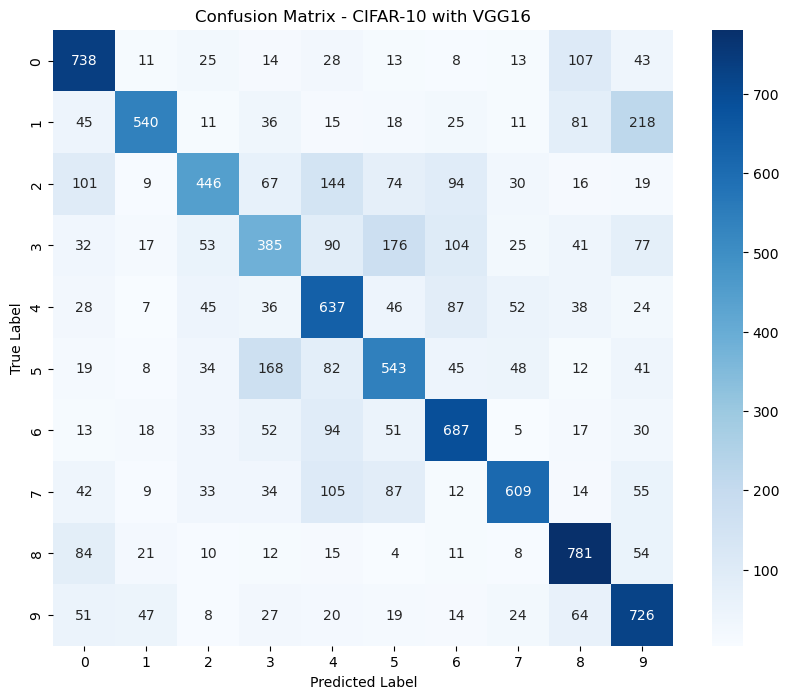

In [ ]:
# Afficher la matrice de confusion
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - CIFAR-10 with VGG16')
plt.show()

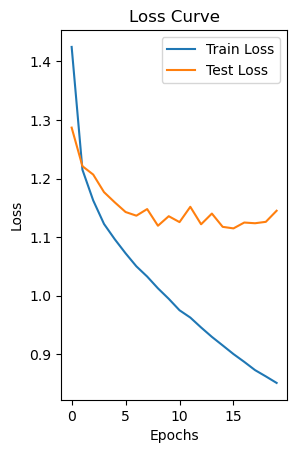

In [ ]:
# Loss
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Test Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Loss Curve')
plt.legend()
